# 🩸 Proje 2 · Bölüm 1 — Diyabet veri setini tanıyalım
**Seviye: Başlangıç**

Bu projede **tablo hâlindeki klinik verilerden** (glukoz, VKİ, yaş…) bir kişinin diyabet riskini tahmin eden bir model kuracak ve bunu telefonda çalışan bir **risk hesaplayıcıya** dönüştüreceğiz.

| Bölüm | Konu | Seviye |
|---|---|---|
| **2.1 (bu dosya)** | Veriyi tanıma, eksik/hatalı değerler, keşifsel analiz | Başlangıç |
| 2.2 | İlk model: lojistik regresyon; duyarlılık, özgüllük, eşik | Orta |
| 2.3 | Model karşılaştırma, kalibrasyon, karar eğrisi analizi | İleri |
| 2.4 | Açıklanabilirlik, alt grup adaleti ve mobil uygulama | İleri |

**Veri seti: Pima Indians Diabetes Database** (ABD Ulusal Diyabet, Sindirim ve Böbrek Hastalıkları Enstitüsü — NIDDK; UCI ML deposu). Arizona'daki Pima topluluğundan **21 yaş üstü 768 kadın**. Sonuç: 5 yıl içinde diyabet tanısı (WHO kriterleri).

> ⚠️ Bu veri seti tek bir etnik topluluktan ve yalnızca kadınlardan oluşur → **genellenebilirlik** sınırlıdır. Bu, bölüm 2.4'te tartışacağımız önemli bir konudur.

In [1]:
# Google Colab'da çalışıyorsanız proje klasörünü (zip) yükleyin
import os, sys
if "google.colab" in sys.modules and not os.path.exists("veri"):
    from google.colab import files
    print("Lütfen 02_Diyabet.zip dosyasını seçin"); files.upload()
    !unzip -q -o 02_Diyabet.zip
    %cd 02_Diyabet
print("Çalışma klasörü:", os.getcwd())

Çalışma klasörü: /home/claude/SaglikYZ/02_Diyabet


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, json, warnings
warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
sns.set_theme(style="whitegrid", font_scale=0.9)
OZELLIKLER = ["Gebelik", "Glukoz", "KanBasinci", "DeriKalinligi", "Insulin", "VKI", "SoygecmisSkoru", "Yas"]

ham = pd.read_csv("veri/diabetes_orijinal.csv")
ham.columns = OZELLIKLER + ["Diyabet"]
print("Satır (kişi):", len(ham), "| Sütun:", ham.shape[1])
ham.head(8)

Satır (kişi): 768 | Sütun: 9


,Gebelik,Glukoz,KanBasinci,DeriKalinligi,Insulin,VKI,SoygecmisSkoru,Yas,Diyabet
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0


## 1. Değişkenler ne anlama geliyor?
| Değişken | Açıklama | Birim |
|---|---|---|
| Gebelik | Gebelik sayısı | adet |
| Glukoz | Oral glukoz tolerans testinde 2. saat plazma glukozu | mg/dL |
| KanBasinci | Diyastolik kan basıncı | mmHg |
| DeriKalinligi | Triseps deri kıvrım kalınlığı | mm |
| Insulin | 2. saat serum insülini | µU/mL |
| VKI | Vücut kitle indeksi | kg/m² |
| SoygecmisSkoru | *Diabetes Pedigree Function*: aile öyküsüne dayalı genetik yatkınlık skoru | — |
| Yas | Yaş | yıl |
| **Diyabet** | 5 yıl içinde diyabet tanısı (1 = evet) | — |

In [3]:
ham.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Gebelik,768.0,3.8,3.4,0.0,1.0,3.0,6.0,17.0
Glukoz,768.0,120.9,32.0,0.0,99.0,117.0,140.2,199.0
KanBasinci,768.0,69.1,19.4,0.0,62.0,72.0,80.0,122.0
DeriKalinligi,768.0,20.5,16.0,0.0,0.0,23.0,32.0,99.0
Insulin,768.0,79.8,115.2,0.0,0.0,30.5,127.2,846.0
VKI,768.0,32.0,7.9,0.0,27.3,32.0,36.6,67.1
SoygecmisSkoru,768.0,0.5,0.3,0.1,0.2,0.4,0.6,2.4
Yas,768.0,33.2,11.8,21.0,24.0,29.0,41.0,81.0
Diyabet,768.0,0.3,0.5,0.0,0.0,0.0,1.0,1.0


## 2. Klinik açıdan imkânsız değerler 🔎
Tabloya bir hekim gözüyle bakınca bir şey dikkat çekiyor: **glukoz = 0, kan basıncı = 0, VKİ = 0** olan kişiler var. Bunlar biyolojik olarak imkânsızdır → aslında **ölçülmemiş (eksik)** değerlerdir ve veri girişinde 0 yazılmıştır.

Bu, işbirliğinde **hekimin en kritik katkısıdır**: bir mühendis bu sıfırları gerçek değer sanıp modele verebilir.

In [4]:
imkansiz = ["Glukoz", "KanBasinci", "DeriKalinligi", "Insulin", "VKI"]
sifir = (ham[imkansiz] == 0).sum()
pd.DataFrame({"0 olan kişi sayısı": sifir, "oran (%)": (100 * sifir / len(ham)).round(1)})

,0 olan kişi sayısı,oran (%)
Glukoz,5,0.7
KanBasinci,35,4.6
DeriKalinligi,227,29.6
Insulin,374,48.7
VKI,11,1.4


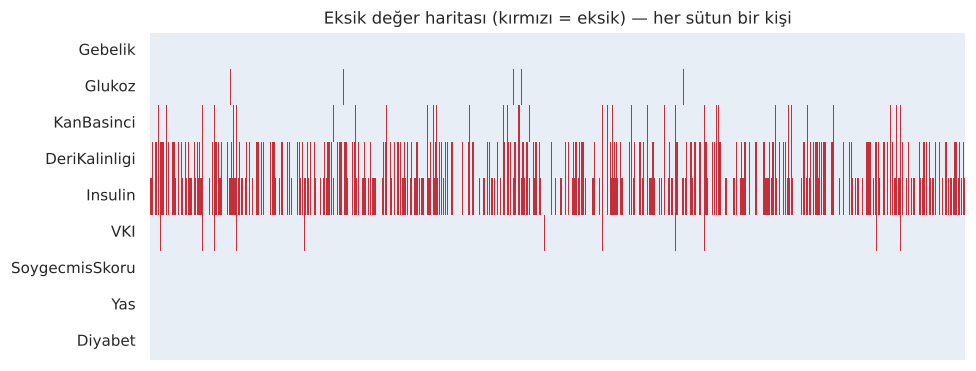

En az bir eksik değeri olan kişi oranı: % 49.0


In [5]:
veri = ham.copy()
veri[imkansiz] = veri[imkansiz].replace(0, np.nan)

fig, ax = plt.subplots(figsize=(9, 3.5))
sns.heatmap(veri.isna().T, cbar=False, cmap=["#e8eef6", "#c62f3a"], ax=ax, xticklabels=False)
ax.set_title("Eksik değer haritası (kırmızı = eksik) — her sütun bir kişi"); plt.tight_layout(); plt.show()
print("En az bir eksik değeri olan kişi oranı: %", round(100 * veri.isna().any(axis=1).mean(), 1))

İnsülin değerlerinin **yarısı** eksik! Bu kişileri silmek veri setini yarıya indirir. Bunun yerine eksik değerleri **medyan ile doldurma (imputasyon)** yapacağız — ve bunu **yalnızca eğitim verisinden öğrenerek** yapacağız (bkz. bölüm 2.2).

## 3. Diyabetliler ile diyabetsizler arasında fark var mı?

Diyabet oranı: % 34.9 → her 3 kişiden yaklaşık 1'i


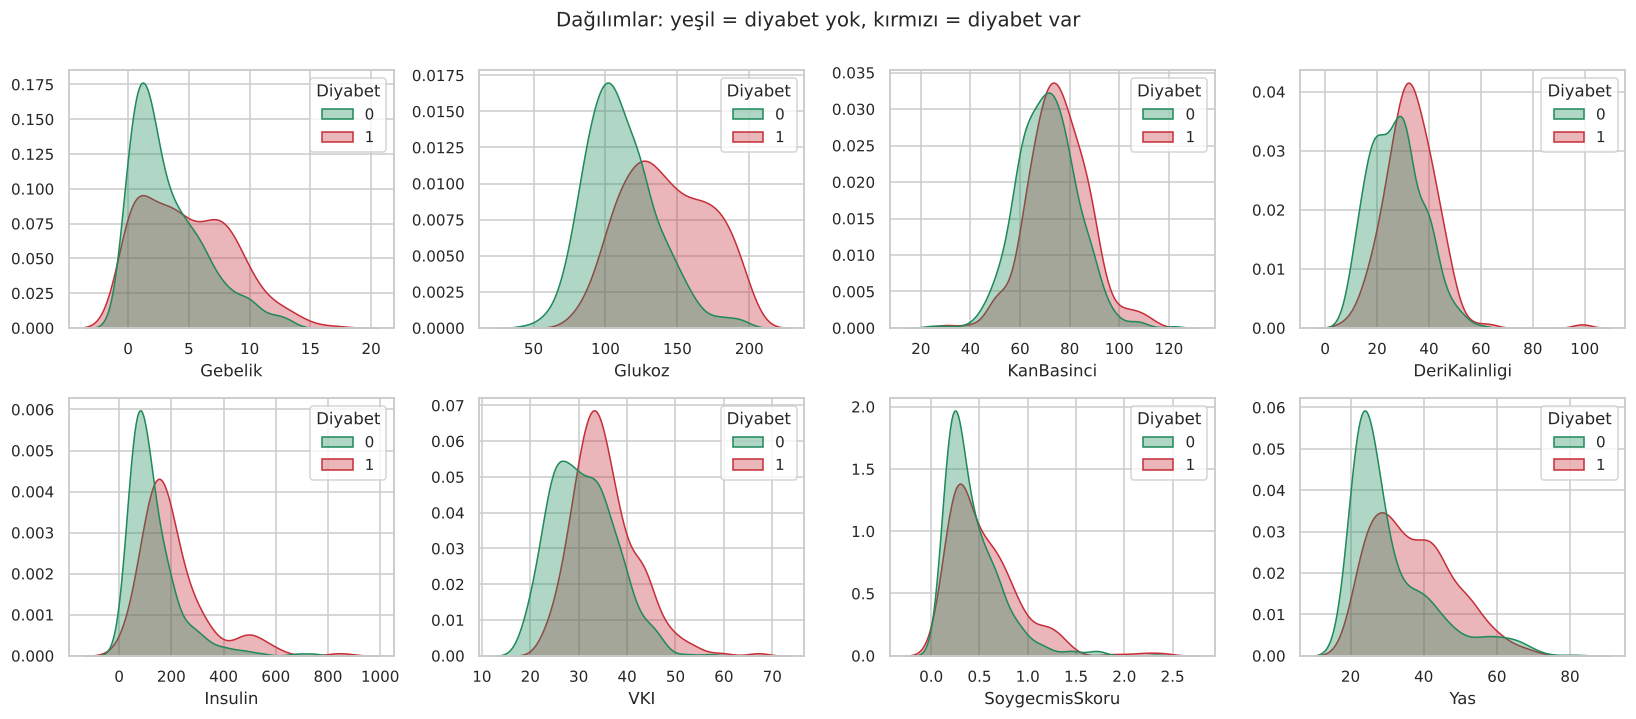

In [6]:
print("Diyabet oranı: %", round(100 * veri.Diyabet.mean(), 1), "→ her 3 kişiden yaklaşık 1'i")
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for a, s in zip(axes.ravel(), OZELLIKLER):
    sns.kdeplot(data=veri, x=s, hue="Diyabet", fill=True, common_norm=False, ax=a, palette=["#1f8a5b", "#c62f3a"], alpha=.35)
    a.set_ylabel("")
plt.suptitle("Dağılımlar: yeşil = diyabet yok, kırmızı = diyabet var", y=1.0); plt.tight_layout(); plt.show()

In [7]:
from scipy import stats
satir = []
for s in OZELLIKLER:
    a, b = veri.loc[veri.Diyabet == 0, s].dropna(), veri.loc[veri.Diyabet == 1, s].dropna()
    satir.append({"Değişken": s, "Diyabet yok (medyan)": a.median(), "Diyabet var (medyan)": b.median(),
                  "p (Mann-Whitney)": stats.mannwhitneyu(a, b).pvalue})
tablo1 = pd.DataFrame(satir).set_index("Değişken")
tablo1["p (Mann-Whitney)"] = tablo1["p (Mann-Whitney)"].map(lambda p: "<0,001" if p < 0.001 else f"{p:.3f}")
tablo1.round(2)

,Diyabet yok (medyan),Diyabet var (medyan),p (Mann-Whitney)
Değişken,,,
Gebelik,2.00,4.00,"<0,001"
Glukoz,107.00,140.00,"<0,001"
KanBasinci,70.00,74.50,"<0,001"
DeriKalinligi,27.00,32.00,"<0,001"
Insulin,102.50,169.50,"<0,001"
VKI,30.10,34.30,"<0,001"
SoygecmisSkoru,0.34,0.45,"<0,001"
Yas,27.00,36.00,"<0,001"


Bu tablo makalelerdeki klasik **"Tablo 1"**dir. Klasik istatistik bize *grupların ortalamada farklı olduğunu* söyler; makine öğrenmesi ise *tek bir kişi için tahmin* yapmaya çalışır. İkisi farklı sorulardır.

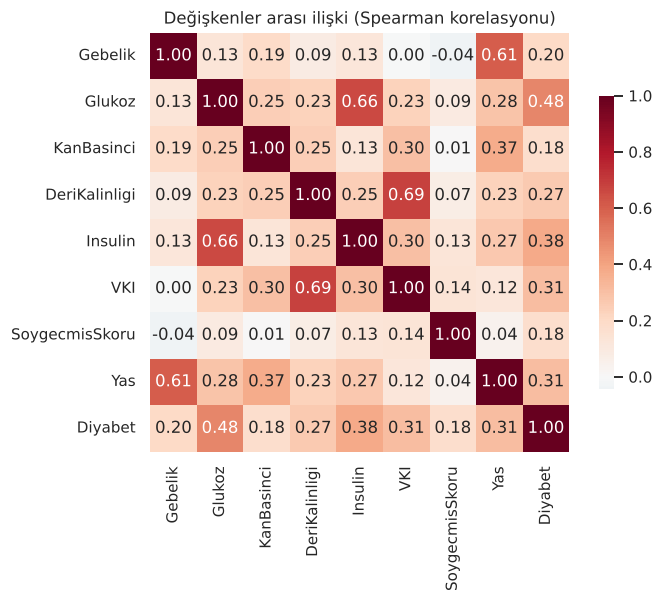

In [8]:
plt.figure(figsize=(7, 5.6))
sns.heatmap(veri.corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Değişkenler arası ilişki (Spearman korelasyonu)"); plt.tight_layout(); plt.show()

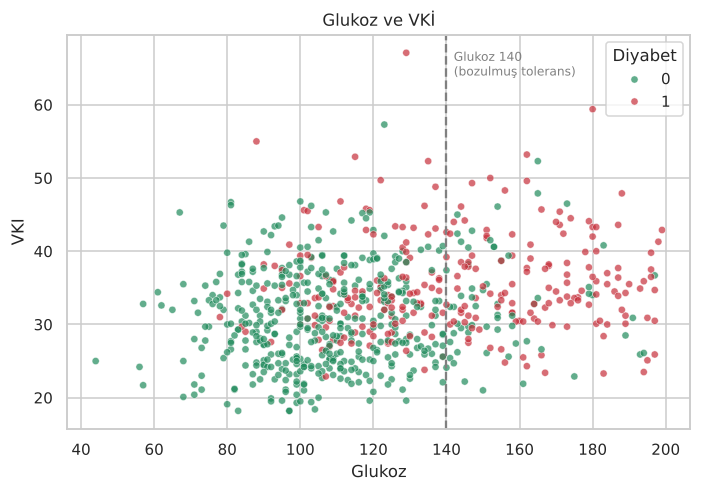

In [9]:
# Glukoz ve VKİ birlikte: iki boyutta bile gruplar iç içe → tek bir eşikle mükemmel ayırmak mümkün değil
plt.figure(figsize=(6.5, 4.6))
sns.scatterplot(data=veri, x="Glukoz", y="VKI", hue="Diyabet", palette=["#1f8a5b", "#c62f3a"], alpha=.7, s=22)
plt.axvline(140, ls="--", c="gray"); plt.text(142, 64, "Glukoz 140\n(bozulmuş tolerans)", fontsize=8, color="gray")
plt.title("Glukoz ve VKİ"); plt.tight_layout(); plt.show()

In [10]:
veri.to_csv("veri/diyabet_temiz.csv", index=False)
print("Temizlenmiş veri kaydedildi → veri/diyabet_temiz.csv (eksikler NaN olarak)")

Temizlenmiş veri kaydedildi → veri/diyabet_temiz.csv (eksikler NaN olarak)


## ✅ Bu bölümde öğrendiklerimiz
* Tablo verisinde her **satır bir hasta**, her **sütun bir özellik**tir.
* **Klinik bilgi** olmadan veri doğru temizlenemez (0 glukoz = eksik veri).
* Eksik verinin **mekanizması** önemlidir: insülin neden ölçülmemiş? Rastgele mi, yoksa belli hastalarda mı? (Araştırma sorusu!)

➡️ Sonraki bölüm: **2.2 İlk model**